In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
%matplotlib inline

Load Dataset

In [2]:
df = pd.read_csv("data/covid19.csv")
df.head()

,continent,country,population,date,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests
0,Africa,Eritrea,3662244.0,16-02-2026,NaN,0.0,2782.0,10189,NaN,28.0,103.0,6470.0,23693.0
1,Africa,Niger,26083660.0,16-02-2026,NaN,729.0,381.0,9931,NaN,12.0,312.0,9759.0,254538.0
2,Africa,Saint-Helena,6115.0,16-02-2026,NaN,2164.0,354211.0,2166,NaN,NaN,NaN,NaN,NaN
3,South-America,Falkland-Islands,3539.0,16-02-2026,NaN,0.0,545352.0,1930,NaN,NaN,NaN,2439107.0,8632.0
4,North-America,Montserrat,4965.0,16-02-2026,NaN,19.0,282578.0,1403,NaN,1611.0,8.0,3577442.0,17762.0


Basic Information

In [3]:
print("Shape :", df.shape)
print()

print(df.info())

Shape : (238, 13)

<class 'pandas.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   continent           236 non-null    str    
 1   country             238 non-null    str    
 2   population          229 non-null    float64
 3   date                238 non-null    str    
 4   new_cases           17 non-null     float64
 5   active_cases        191 non-null    float64
 6   cases_per_million   230 non-null    float64
 7   total_cases         238 non-null    int64  
 8   new_deaths          3 non-null      float64
 9   deaths_per_million  225 non-null    float64
 10  total_deaths        233 non-null    float64
 11  tests_per_million   213 non-null    float64
 12  total_tests         213 non-null    float64
dtypes: float64(9), int64(1), str(3)
memory usage: 24.3 KB
None


Dataset Summary

In [4]:
df.describe(include="all")

,continent,country,population,date,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests
count,236,238,2.290000e+02,238,17.000000,1.910000e+02,230.000000,2.380000e+02,3.000000,225.000000,2.330000e+02,2.130000e+02,2.130000e+02
unique,7,238,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Africa,Eritrea,NaN,16-02-2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,59,1,NaN,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,3.469404e+07,NaN,103.058824,2.636781e+05,202460.960870,8.883449e+06,3.333333,1275.668444,9.026621e+04,2.155978e+06,3.298829e+07
std,NaN,NaN,1.386374e+08,NaN,212.516608,1.923405e+06,205838.075508,5.193031e+07,4.163332,1307.746257,5.163434e+05,3.647972e+06,1.198779e+08
min,NaN,NaN,7.990000e+02,NaN,0.000000,0.000000e+00,16.000000,9.000000e+00,0.000000,2.000000,1.000000e+00,5.093000e+03,7.850000e+03
25%,NaN,NaN,4.454310e+05,NaN,10.000000,4.550000e+01,19423.250000,2.741875e+04,1.000000,176.000000,2.250000e+02,1.981990e+05,3.478150e+05
50%,NaN,NaN,5.797805e+06,NaN,13.000000,6.620000e+02,128762.000000,2.320425e+05,2.000000,869.000000,2.570000e+03,8.851190e+05,2.226216e+06
75%,NaN,NaN,2.210284e+07,NaN,63.000000,8.017500e+03,331302.750000,1.565481e+06,5.000000,2092.000000,1.805700e+04,2.439107e+06,1.346373e+07


Missing Values

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

new_deaths            235
new_cases             221
active_cases           47
total_tests            25
tests_per_million      25
deaths_per_million     13
population              9
cases_per_million       8
total_deaths            5
continent               2
dtype: int64

Missing Value Percentage

In [6]:
missing_percent = (df.isnull().sum()/len(df))*100
missing_percent = missing_percent.sort_values(ascending=False)
missing_percent

new_deaths            98.739496
new_cases             92.857143
active_cases          19.747899
total_tests           10.504202
tests_per_million     10.504202
deaths_per_million     5.462185
population             3.781513
cases_per_million      3.361345
total_deaths           2.100840
continent              0.840336
country                0.000000
date                   0.000000
total_cases            0.000000
dtype: float64

Convert Date Column

In [7]:
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df.head()

,continent,country,population,date,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests
0,Africa,Eritrea,3662244.0,2026-02-16,NaN,0.0,2782.0,10189,NaN,28.0,103.0,6470.0,23693.0
1,Africa,Niger,26083660.0,2026-02-16,NaN,729.0,381.0,9931,NaN,12.0,312.0,9759.0,254538.0
2,Africa,Saint-Helena,6115.0,2026-02-16,NaN,2164.0,354211.0,2166,NaN,NaN,NaN,NaN,NaN
3,South-America,Falkland-Islands,3539.0,2026-02-16,NaN,0.0,545352.0,1930,NaN,NaN,NaN,2439107.0,8632.0
4,North-America,Montserrat,4965.0,2026-02-16,NaN,19.0,282578.0,1403,NaN,1611.0,8.0,3577442.0,17762.0


Convert Numeric Columns

In [8]:
numeric_cols = [
    "population",
    "new_cases",
    "active_cases",
    "cases_per_million",
    "total_cases",
    "new_deaths",
    "deaths_per_million",
    "total_deaths",
    "tests_per_million",
    "total_tests"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

Remove World Summary Rows

In [9]:
summary = [
    "All",
    "Africa",
    "Asia",
    "Europe",
    "North-America",
    "South-America",
    "Oceania"
]

country_df = df[~df["country"].isin(summary)]
country_df.head()

,continent,country,population,date,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests
0,Africa,Eritrea,3662244.0,2026-02-16,NaN,0.0,2782.0,10189,NaN,28.0,103.0,6470.0,23693.0
1,Africa,Niger,26083660.0,2026-02-16,NaN,729.0,381.0,9931,NaN,12.0,312.0,9759.0,254538.0
2,Africa,Saint-Helena,6115.0,2026-02-16,NaN,2164.0,354211.0,2166,NaN,NaN,NaN,NaN,NaN
3,South-America,Falkland-Islands,3539.0,2026-02-16,NaN,0.0,545352.0,1930,NaN,NaN,NaN,2439107.0,8632.0
4,North-America,Montserrat,4965.0,2026-02-16,NaN,19.0,282578.0,1403,NaN,1611.0,8.0,3577442.0,17762.0


Number of Countries

In [10]:
country_df["country"].nunique()

231

Countries Per Continent

In [11]:
country_df.groupby("continent")["country"].count().sort_values()

continent
South-America    14
Oceania          20
North-America    39
Europe           48
Asia             50
Africa           58
Name: country, dtype: int64

Visualization

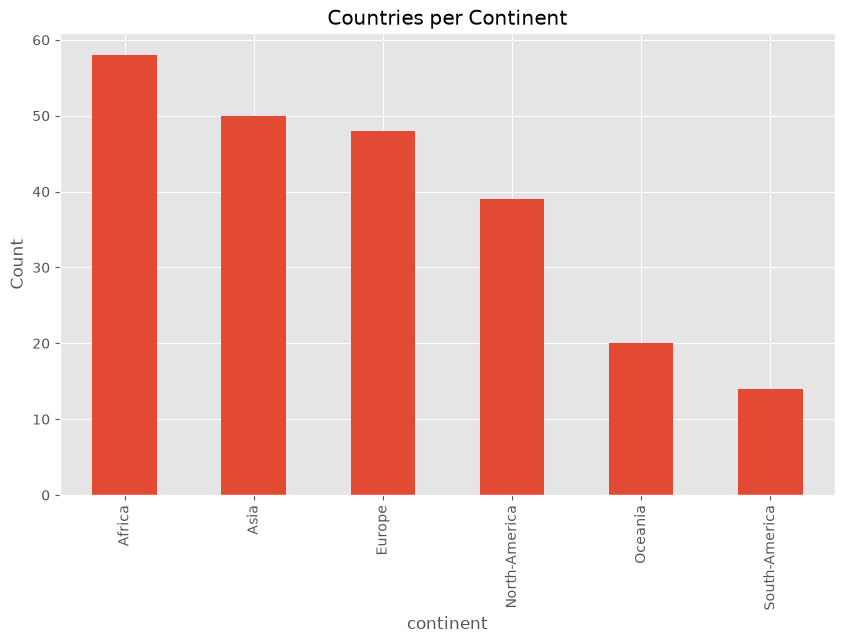

In [12]:
plt.figure(figsize=(10,6))
country_df.groupby("continent")["country"].count().plot(kind="bar")
plt.title("Countries per Continent")
plt.ylabel("Count")
plt.show()

Top 10 Countries by Total Cases

In [13]:
top_cases = country_df.sort_values(
    "total_cases",
    ascending=False
).head(10)

top_cases[["country","total_cases"]]

,country,total_cases
225,USA,111820082
226,India,45035393
227,France,40138560
228,Germany,38828995
229,Brazil,38743918
230,S-Korea,34571873
231,Japan,33803572
232,Italy,26723249
233,UK,24910387
234,Russia,24124215


Top 10 Cases

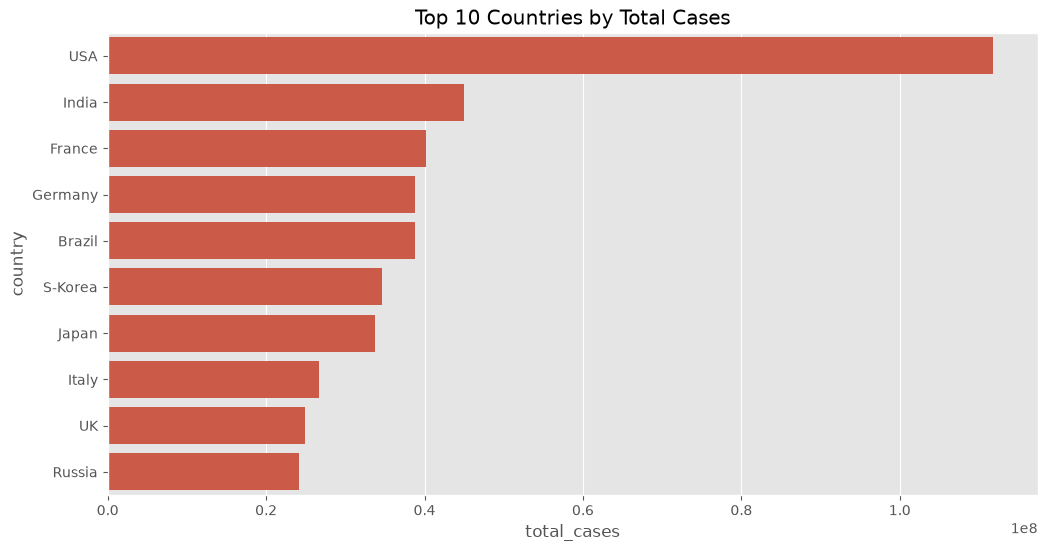

In [14]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_cases,
    x="total_cases",
    y="country"
)

plt.title("Top 10 Countries by Total Cases")
plt.show()

Top 10 Deaths

In [15]:
top_deaths = country_df.sort_values(
    "total_deaths",
    ascending=False
).head(10)

top_deaths[["country","total_deaths"]]

,country,total_deaths
225,USA,1219487.0
229,Brazil,711380.0
226,India,533570.0
234,Russia,402756.0
187,Mexico,334958.0
233,UK,232112.0
202,Peru,222161.0
232,Italy,196487.0
228,Germany,183027.0
227,France,167642.0


Death Plot

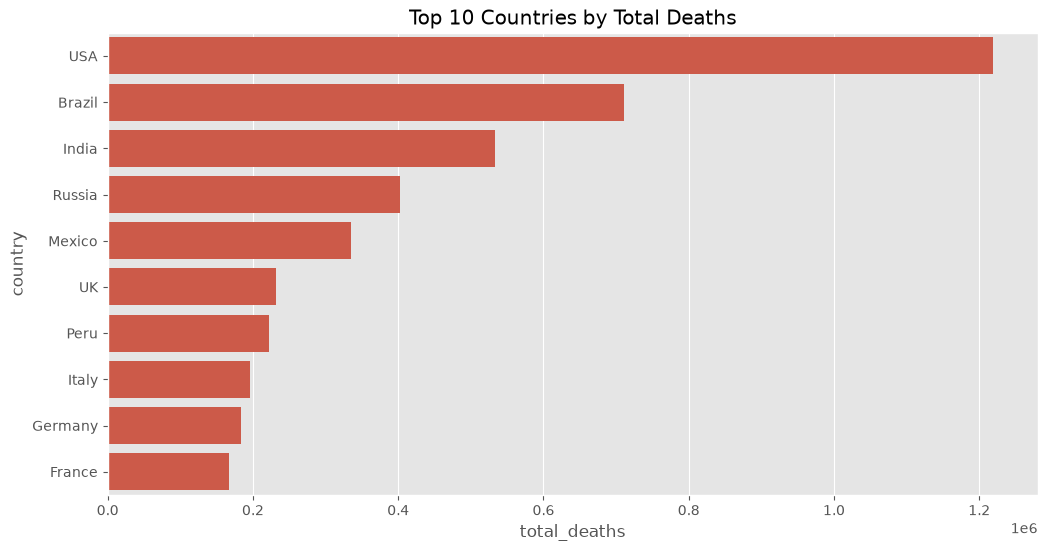

In [16]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_deaths,
    x="total_deaths",
    y="country"
)

plt.title("Top 10 Countries by Total Deaths")
plt.show()

Top Population

In [17]:
country_df.sort_values(
    "population",
    ascending=False
)[["country","population"]].head(10)

,country,population
9,China,1.448471e+09
226,India,1.406632e+09
225,USA,3.348053e+08
189,Indonesia,2.791345e+08
147,Pakistan,2.294890e+08
126,Nigeria,2.167469e+08
229,Brazil,2.153536e+08
214,Bangladesh,1.678857e+08
234,Russia,1.458059e+08
187,Mexico,1.315628e+08


Cases Per Million

In [18]:
top_case_rate = country_df.sort_values(
    "cases_per_million",
    ascending=False
).head(10)

top_case_rate[["country","cases_per_million"]]

,country,cases_per_million
121,Brunei,771655.0
55,San-Marino,768226.0
49,Faeroe-Islands,703959.0
230,S-Korea,673523.0
193,Austria,670727.0
33,Niue,652898.0
151,Slovenia,652803.0
100,Andorra,619844.0
130,Martinique,615777.0
227,France,612013.0


Tests Per Million

In [19]:
top_tests = country_df.sort_values(
    "tests_per_million",
    ascending=False
).head(10)

top_tests[["country","tests_per_million"]]

,country,tests_per_million
193,Austria,23302116.0
206,Denmark,22165247.0
162,UAE,19910389.0
42,Bermuda,16622128.0
59,Gibraltar,15852213.0
49,Faeroe-Islands,15802409.0
28,Turks-and-Caicos,15520193.0
217,Spain,10082298.0
208,Hong-Kong,10011143.0
192,Greece,9909078.0


Correlation Matrix

In [20]:
corr = country_df[numeric_cols].corr()
corr

,population,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests
population,1.000000,0.833754,0.255569,-0.139290,0.367741,1.0,-0.076639,0.404331,-0.088925,0.540603
new_cases,0.833754,1.000000,0.454481,0.066752,0.881173,1.0,0.475571,0.984654,0.241257,0.760787
active_cases,0.255569,0.454481,1.000000,0.022301,0.569577,1.0,0.158905,0.700091,-0.039086,0.349332
cases_per_million,-0.139290,0.066752,0.022301,1.000000,0.164528,-1.0,0.470420,0.031756,0.546706,0.092359
total_cases,0.367741,0.881173,0.569577,0.164528,1.000000,1.0,0.223258,0.886136,0.052352,0.837956
new_deaths,1.000000,1.000000,1.000000,-1.000000,1.000000,1.0,-1.000000,1.000000,-1.000000,1.000000
deaths_per_million,-0.076639,0.475571,0.158905,0.470420,0.223258,-1.0,1.000000,0.288021,0.241053,0.173297
total_deaths,0.404331,0.984654,0.700091,0.031756,0.886136,1.0,0.288021,1.000000,0.000133,0.801020
tests_per_million,-0.088925,0.241257,-0.039086,0.546706,0.052352,-1.0,0.241053,0.000133,1.000000,0.202019
total_tests,0.540603,0.760787,0.349332,0.092359,0.837956,1.0,0.173297,0.801020,0.202019,1.000000


Heatmap

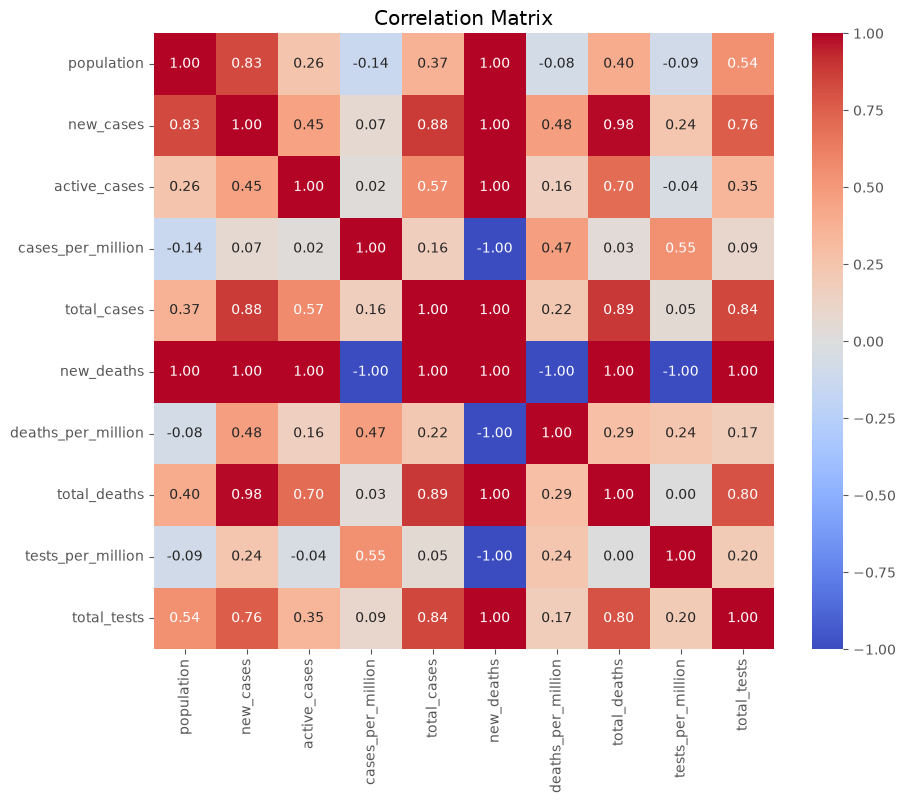

In [21]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

Scatter Plot

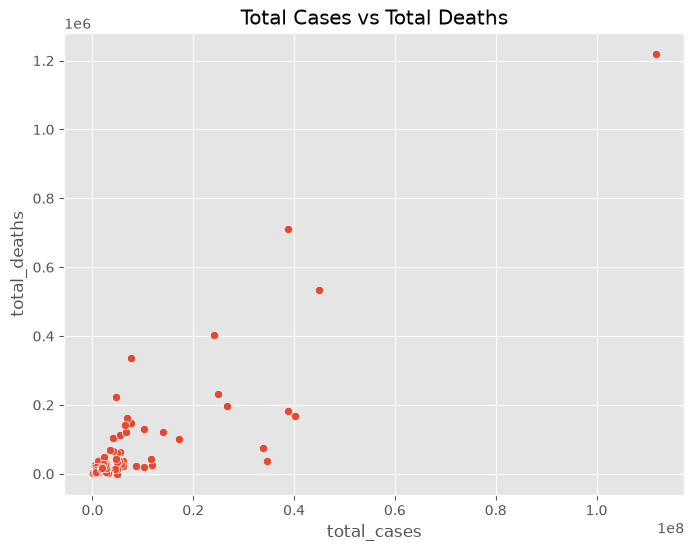

In [22]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=country_df,
    x="total_cases",
    y="total_deaths"
)

plt.title("Total Cases vs Total Deaths")
plt.show()

Recovery Proxy

In [23]:
country_df["Closed_Cases"] = (
    country_df["total_cases"] -
    country_df["active_cases"]
)

country_df.head()

,continent,country,population,date,new_cases,active_cases,cases_per_million,total_cases,new_deaths,deaths_per_million,total_deaths,tests_per_million,total_tests,Closed_Cases
0,Africa,Eritrea,3662244.0,2026-02-16,NaN,0.0,2782.0,10189,NaN,28.0,103.0,6470.0,23693.0,10189.0
1,Africa,Niger,26083660.0,2026-02-16,NaN,729.0,381.0,9931,NaN,12.0,312.0,9759.0,254538.0,9202.0
2,Africa,Saint-Helena,6115.0,2026-02-16,NaN,2164.0,354211.0,2166,NaN,NaN,NaN,NaN,NaN,2.0
3,South-America,Falkland-Islands,3539.0,2026-02-16,NaN,0.0,545352.0,1930,NaN,NaN,NaN,2439107.0,8632.0,1930.0
4,North-America,Montserrat,4965.0,2026-02-16,NaN,19.0,282578.0,1403,NaN,1611.0,8.0,3577442.0,17762.0,1384.0


Top Active Cases

In [24]:
country_df.sort_values(
    "active_cases",
    ascending=False
)[["country","active_cases"]].head(10)

,country,active_cases
229,Brazil,1783377.0
237,Vietnam,941018.0
225,USA,786167.0
187,Mexico,467986.0
228,Germany,405368.0
234,Russia,175641.0
232,Italy,165544.0
156,Lebanon,145299.0
9,China,118977.0
121,Brunei,99893.0


Top New Cases

In [25]:
country_df.sort_values(
    "new_cases",
    ascending=False
)[["country","new_cases"]].head(10)

,country,new_cases
217,Spain,702.0
182,South-Africa,614.0
107,Uzbekistan,136.0
72,Channel-Islands,91.0
145,Kazakhstan,63.0
43,Gambia,28.0
109,Qatar,28.0
73,Mayotte,19.0
71,French-Guiana,13.0
42,Bermuda,11.0


Top New Deaths

In [26]:
country_df.sort_values(
    "new_deaths",
    ascending=False
)[["country","new_deaths"]].head(10)

,country,new_deaths
217,Spain,8.0
42,Bermuda,2.0
0,Eritrea,NaN
1,Niger,NaN
2,Saint-Helena,NaN
3,Falkland-Islands,NaN
4,Montserrat,NaN
5,Diamond-Princess,NaN
6,Vatican-City,NaN
7,Western-Sahara,NaN


Save Clean Dataset

In [27]:
country_df.to_csv("covid_cleaned.csv", index=False)
print("Cleaned dataset saved.")

Cleaned dataset saved.
